# The junction as a minimum cut of the nuclei graph

**The junction finder now** cuts a grid of 5 µm pixels between two seeds (one in each organoid): each pixel is as dear to cut as the nuclear stain is bright round it, so a dark line between the organoids is cheap, and the cut is straightened afterwards (`junction.find_junction`, defaults: bend 1000 µm, no-seam fallback). Called **pixel cut** below.

**The idea tested here:** cut between **nuclei** instead of pixels. Every nucleus Cellpose found is a node; neighbouring nuclei are joined; the cut runs between nuclei, and what cutting an edge costs comes from the graph itself:

- **the graph**: a **Gabriel graph** — two nuclei are joined when no third nucleus lies in the circle that has them as its diameter: the neighbours that see each other directly, without the long thin edges a Delaunay triangulation (the Voronoi diagram's dual) adds past a third nucleus. Delaunay is run too, for comparison. Edges longer than 60 µm are dropped (holes, tears);
- **what an edge costs to cut** (factors multiplied):
  - *uniform* — every edge 1: the cut crossing the fewest edges;
  - *1/length*, *1/length²* (scaled by the median edge) — a long edge, between sparse nuclei, is cheap: the dark line between two organoids *is* fewer nuclei;
  - *(local length)^-p* — the edge's length over the typical edge within 60 µm of its two ends, to the power p = 3, 6 or 10 (clipped to 0.3–3×): the pixel finder's own recipe, which divides the stain by its 60 µm surroundings and raises it to the power 6. Added after a first round showed 1/length² far too weak (section 2);
  - *degree* — the fewer neighbours the two nuclei have (the lesser of the two, over the median), the cheaper: nuclei on the edge of a gap;
  - *density* — the fewer nuclei within 25 µm of the two ends, the cheaper;
  - *label change* — each cell's own AF488 − AF555 (each scaled 0–1 over the cells), averaged over the cells within 50 µm; an edge across which it changes fast is cheaper, down to ×0.3 (the pixel finder's `label_change` measured on cells).

**Everything else is the pixel finder's**, so only the cut differs: the same overview, tissue and **seeds** (`find_junction` with the defaults, nuclei inside a seed tied to it), and the same line from the two halves (`trace_interface`, each overview pixel taking the side of its nearest nucleus). The pixel finder's straightening is not applied to the graph cut (on a flat price it redraws the same line from the seeds whatever the cut was).

**The data:** the 138 sections with a hand-drawn junction (`02_junction_seeding`'s set, its tuning / held-out split), each with its nuclei from the newest cells-analysis run (131) or `count_cells.py` (7) — nothing is segmented again. **Scored** as in `02_junction_seeding`: mean symmetric distance between the found and the hand-drawn line over the tissue, **capped at 300 µm** (no line: 300). Lower is better.

Computed by `nuclei_graph.py` (~10 s a section) into `junction_eval/graph/`; this notebook only reads it.

In [1]:
from pathlib import Path
import json
import ssl
import sys
import warnings

try:
    ssl.create_default_context()
except ssl.SSLError:
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "microscopy_viewer").is_dir())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(Path.cwd()))
sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

import nuclei_graph as NG
import junction_tuning as jt

PIXEL = "pixel cut (the finder's defaults)"
SECTIONS = pd.read_csv(NG.SECTIONS)
RESULTS = pd.read_json(NG.RESULTS, lines=True).drop_duplicates(["name", "variant"], keep="last")
RESULTS = RESULTS.merge(SECTIONS[["name", "set", "batch", "Ripped", "Folded", "Quality"]], on="name", how="left")
WIDE = RESULTS.pivot(index="name", columns="variant", values="capped")
VARIANTS = [PIXEL, *NG.VARIANTS]
WIDE = WIDE[[v for v in VARIANTS if v in WIDE.columns]]
INFO = SECTIONS.set_index("name").loc[WIDE.index]
pixel_rows = RESULTS[RESULTS["variant"] == PIXEL].set_index("name")
INFO["no seam"] = pixel_rows["no_seam_fallback"].reindex(WIDE.index).fillna(False).astype(bool)
print(f"{len(WIDE)} sections ({(INFO['set'] == 'held out').sum()} held out), {len(WIDE.columns)} ways of cutting")
sources = RESULTS.dropna(subset=["source"]).drop_duplicates("name")["source"].value_counts()
print("nuclei from:", dict(sources))

138 sections (45 held out), 15 ways of cutting
nuclei from: {'cells analysis': np.int64(131), 'count_cells': np.int64(7)}


## 1. The premise: what the hand-drawn line crosses in the graph

Before any cut: are the Gabriel edges that cross the hand-drawn junction different from the edges round them? *Crossing*: the two nuclei on opposite sides of the hand-drawn line, the edge's middle within 30 µm of it; *near*: edges whose middle is 30–300 µm from it. Per section, the median of each; the ratio crossing ÷ near, and in how many sections crossing edges are longer (sparser nuclei), their nuclei have fewer neighbours, and the label changes faster across them.

,median ratio,sections where crossing is larger (%),sections where crossing is smaller (%)
length: crossing ÷ near,1.25,100.00,0.00
degree: crossing ÷ near,1.00,8.70,0.72
label change: crossing ÷ near,1.32,78.99,21.01


edges crossing the hand-drawn line per section: median 182; median edge near it 6.7 µm, crossing 8.3 µm


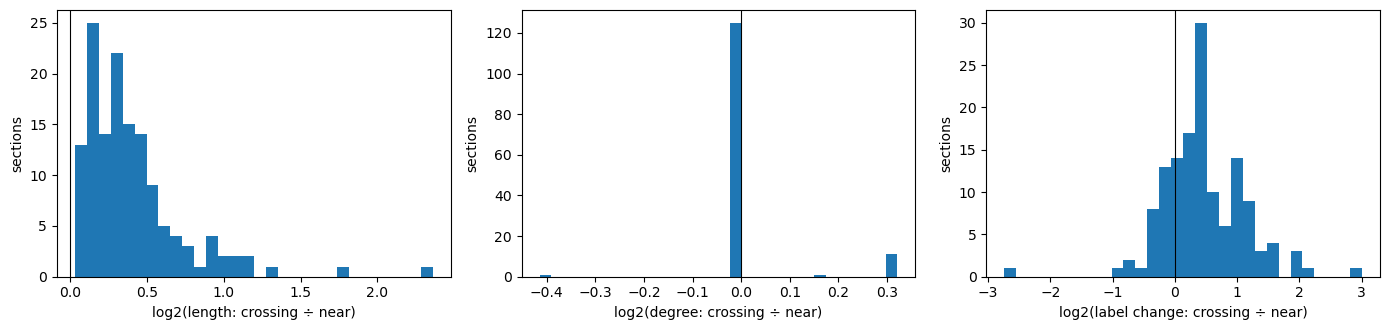

In [2]:
CROSS = pd.read_json(NG.CROSSING, lines=True).drop_duplicates("name", keep="last").set_index("name")
ratios = pd.DataFrame({
    "length: crossing ÷ near": CROSS["length crossing (µm)"] / CROSS["length near (µm)"],
    "degree: crossing ÷ near": CROSS["degree crossing"] / CROSS["degree near"],
    "label change: crossing ÷ near": CROSS["label change crossing (/µm)"] / CROSS["label change near (/µm)"],
})
summary = pd.DataFrame({"median ratio": ratios.median(),
                        "sections where crossing is larger (%)": 100 * (ratios > 1).mean(),
                        "sections where crossing is smaller (%)": 100 * (ratios < 1).mean()})
display(summary.round(2))
print(f"edges crossing the hand-drawn line per section: median {CROSS['crossing'].median():.0f}; "
      f"median edge near it {CROSS['length near (µm)'].median():.1f} µm, crossing {CROSS['length crossing (µm)'].median():.1f} µm")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, column in zip(axes, ratios.columns):
    ax.hist(np.log2(ratios[column].dropna()), bins=30, color="tab:blue")
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel=f"log2({column})", ylabel="sections")
plt.tight_layout()
plt.show()

## 2. How far each cut is from the hand-drawn line

Mean capped distance (µm) per way of cutting: all 138, the tuning and held-out sets, the first 30 (mostly with a dark line) and the 108 added since (many without one), and the sections where the pixel finder found no dark line (its no-seam fallback ran). *Found*: share of sections with a line at all. The best graph variant is chosen on the **tuning** set; held out is what to believe.

In [3]:
def table(frame, info):
    groups = {"all": info.index, "tuning": info.index[info["set"] == "tuning"],
              "held out": info.index[info["set"] == "held out"],
              "first 30": info.index[info["batch"] == "first 31"], "new 108": info.index[info["batch"] == "new"],
              "no dark line (fallback)": info.index[info["no seam"]], "dark line": info.index[~info["no seam"]]}
    out = pd.DataFrame({k: frame.loc[v].mean() for k, v in groups.items()})
    found = RESULTS.pivot(index="name", columns="variant", values="found").reindex(frame.index)
    out["found (%)"] = 100 * found.fillna(False).astype(bool).mean().reindex(out.index)
    out.insert(0, "n", len(frame))
    return out


SCORES = table(WIDE, INFO)
display(SCORES.round(1).style.background_gradient(subset=["all", "tuning", "held out"], cmap="RdYlGn_r"))
print({k: int(v) for k, v in {"tuning": (INFO['set'] == 'tuning').sum(), "held out": (INFO['set'] == 'held out').sum(),
                              "no dark line": INFO['no seam'].sum()}.items()})

,n,all,tuning,held out,first 30,new 108,no dark line (fallback),dark line,found (%)
variant,,,,,,,,,
pixel cut (the finder's defaults),138,139.900000,130.900000,158.500000,66.200000,160.400000,163.500000,121.700000,98.600000
"Gabriel, uniform",138,196.100000,186.300000,216.400000,167.700000,204.000000,180.100000,208.400000,97.800000
"Gabriel, 1/length",138,192.300000,180.400000,217.000000,154.700000,202.800000,183.500000,199.100000,97.800000
"Gabriel, 1/length²",138,192.200000,179.900000,217.400000,154.000000,202.800000,189.600000,194.100000,97.800000
"Gabriel, 1/length², degree",138,192.500000,179.800000,218.700000,153.300000,203.400000,191.200000,193.500000,97.800000
"Gabriel, 1/length², density",138,198.300000,187.200000,221.300000,150.600000,211.600000,202.600000,195.100000,97.800000
"Gabriel, 1/length², label change",138,185.900000,174.100000,210.200000,145.800000,197.000000,184.500000,186.900000,97.800000
"Gabriel, 1/length², degree, label change",138,185.900000,173.700000,211.100000,145.600000,197.100000,182.000000,188.800000,97.800000
"Gabriel, uniform, label change",138,195.600000,183.100000,221.600000,183.400000,199.000000,170.100000,215.300000,97.800000


{'tuning': 93, 'held out': 45, 'no dark line': 60}


**Section by section against the pixel cut.** For each graph variant: in how many sections it is more than 25 µm closer to the hand-drawn line (*better*) or further (*worse*), and the Wilcoxon signed-rank p of the difference, on the held-out set and on all.

better          worse          median change (µm)          mean change (µm)          Wilcoxon p         
set                                         all held out   all held out                all held out              all held out        all held out
variant                                                                                                                                          
Delaunay, 1/length²                          22        3    55       19              4.428    4.988           52.398   59.722      0.000    0.000
Delaunay, 1/length², label change            23        4    51       18              2.467    0.624           42.402   47.094      0.000    0.005
Gabriel, (local length)^-10                  26        6    55       17              5.812    5.648           39.920   44.491      0.000    0.005
Gabriel, (local length)^-3                   20        5    55       19              5.302    8.598           44.841   56.439      0.000    0.002
Gabriel, (local length)^-6                   23        5    59       21              5.791   16.068           46.007   62.674      0.000    0.000
Gabriel, (local length)^-6, label change     24        5    50       16              1.321    6.227           35.491   39.313      0.001    0.007
Gabriel, 1/length                            18        3    56       20              4.764    4.637           52.418   58.538      0.000    0.000
Gabriel, 1/length²                           17        3    56       20             10.991    7.597           52.255   58.886      0.000    0.000
Gabriel, 1/length², degree                   16        2    55       21              6.628    6.135           52.580   60.248      0.000    0.000
Gabriel, 1/length², degree, label change     21        3    53       20              3.004   10.030           45.979   52.600      0.000    0.001
Gabriel, 1/length², density                  18        3    60       22             11.856   13.551           58.448   62.816      0.000    0.000
Gabriel, 1/length², label change             22        3    54       20              4.891    4.988           45.955   51.688      0.000    0.001
Gabriel, uniform                             18        3    58       17             10.407    6.484           56.197   57.927      0.000    0.001
Gabriel, uniform, label change               18        3    58       19             13.084    3.909           55.740   63.062      0.000    0.000

best graph variant on tuning: Gabriel, (local length)^-6, label change


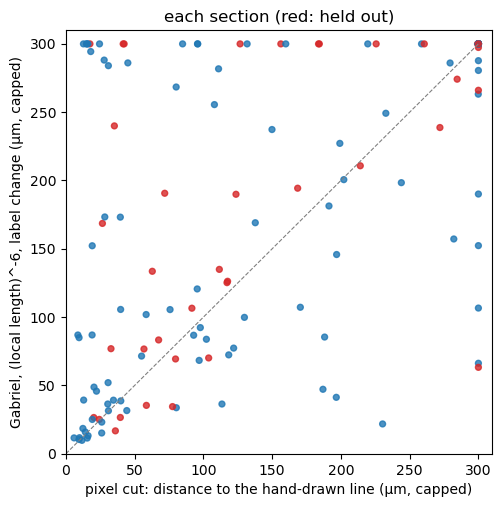

In [4]:
rows = []
for variant in WIDE.columns[1:]:
    for label, names in (("held out", INFO.index[INFO["set"] == "held out"]), ("all", INFO.index)):
        diff = WIDE.loc[names, variant] - WIDE.loc[names, PIXEL]
        p = stats.wilcoxon(diff[diff != 0]).pvalue if (diff != 0).sum() >= 5 else np.nan
        rows.append({"variant": variant, "set": label, "better": int((diff < -25).sum()), "worse": int((diff > 25).sum()),
                     "median change (µm)": float(diff.median()), "mean change (µm)": float(diff.mean()), "Wilcoxon p": p})
PAIRED = pd.DataFrame(rows).pivot(index="variant", columns="set")
display(PAIRED.round(3))

best = SCORES.drop(PIXEL)["tuning"].idxmin()
print(f"best graph variant on tuning: {best}")
fig, ax = plt.subplots(figsize=(5.5, 5.5))
colours = np.where(INFO["set"] == "held out", "tab:red", "tab:blue")
ax.scatter(WIDE[PIXEL], WIDE[best], c=colours, s=18, alpha=0.8)
ax.plot([0, 300], [0, 300], color="grey", lw=0.8, ls="--")
ax.set(xlabel="pixel cut: distance to the hand-drawn line (µm, capped)", ylabel=f"{best} (µm, capped)",
       title="each section (red: held out)", xlim=(0, 310), ylim=(0, 310))
plt.show()

**Pixel or graph, whichever is surer?** If the two disagree in different sections, a section could take the graph cut where the pixel finder found no dark line (its no-seam fallback ran), and the pixel cut where it did. That rule is fixed in advance (it is the pixel finder's own seam test), so it is scored on all sets alike.

In [5]:
combined = np.where(INFO["no seam"], WIDE[best], WIDE[PIXEL])
both = pd.DataFrame({"pixel cut": WIDE[PIXEL], best: WIDE[best],
                     f"graph where no dark line, else pixel": combined}, index=WIDE.index)
display(table(both, INFO).drop(columns=["found (%)"]).round(1))

,n,all,tuning,held out,first 30,new 108,no dark line (fallback),dark line
pixel cut,138,139.9,130.9,158.5,66.2,160.4,163.5,121.7
"Gabriel, (local length)^-6, label change",138,175.4,164.5,197.8,156.0,180.8,172.3,177.8
"graph where no dark line, else pixel",138,143.7,133.9,164.0,74.0,163.1,172.3,121.7


## 3. Pictures

Four sections: the two where the best graph variant gains most over the pixel cut, and the two where it loses most. Left: the overview's nuclear stain with the hand-drawn line (white), the pixel cut (yellow) and two graph cuts (cyan: *Gabriel, 1/length²*; magenta: *Gabriel, (local length)^-6, label change*, the best graph variant). Right: a 400 µm window on the hand-drawn line — every nucleus as a dot coloured by the side the magenta cut put it on, the Gabriel edges in grey, the edges that cut cuts in red.

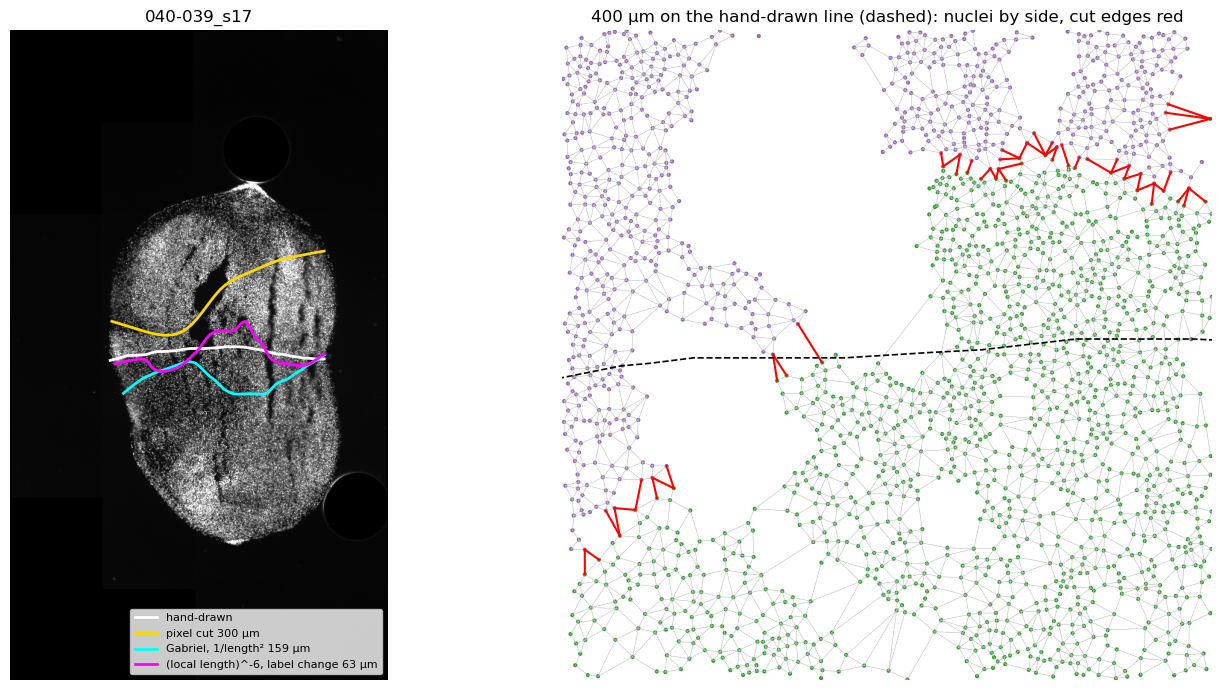

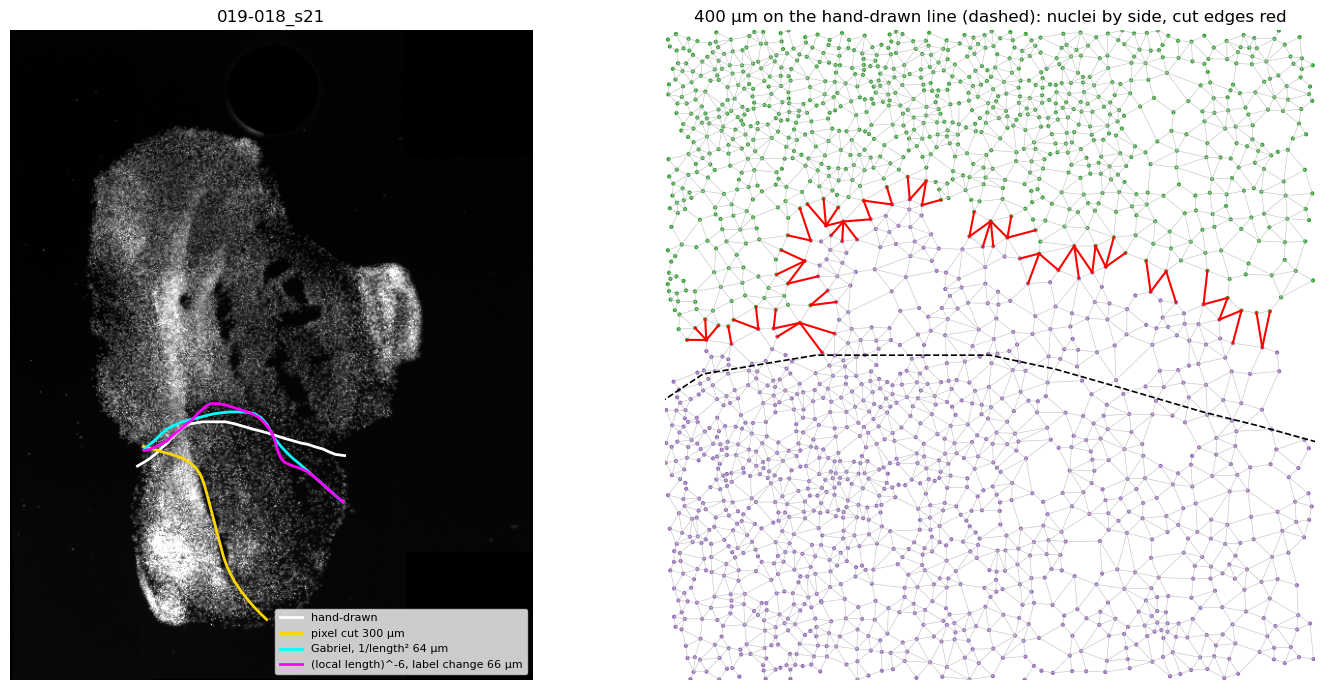

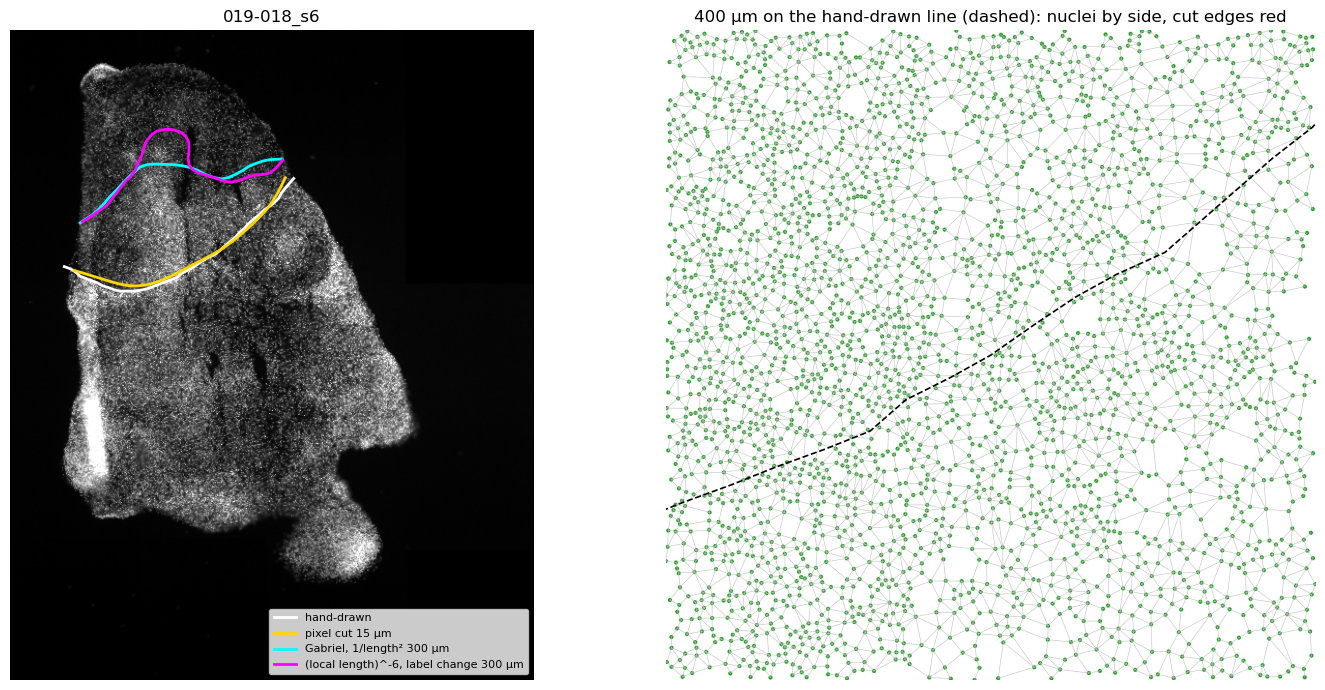

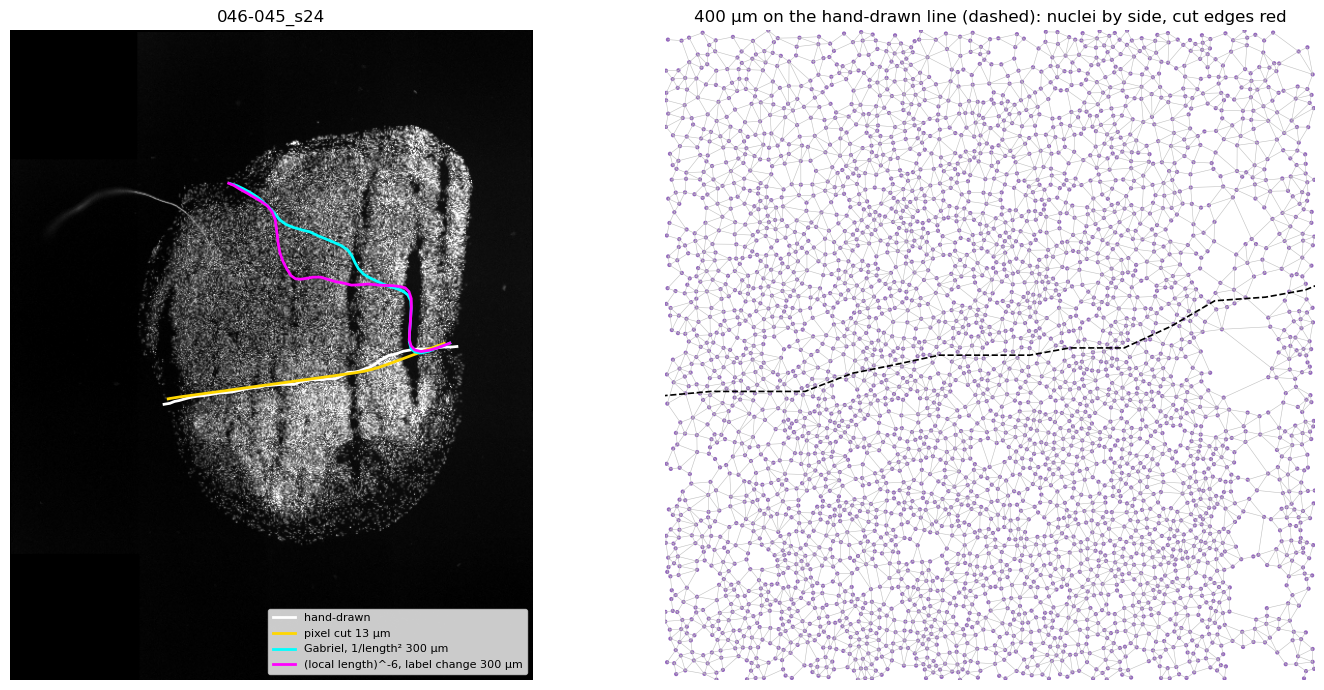

In [6]:
def picture(name):
    overview, _band, manual_line, _base = jt.load_case(name)
    d = np.load(NG.OUT / f"{name}.npz")
    um = float(d["um"])
    stain = overview.channels[overview.nuclear].astype(float)
    low, high = np.percentile(stain[stain > 0], (2, 99.5)) if (stain > 0).any() else (0, 1)
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    axes[0].imshow(np.clip((stain - low) / max(high - low, 1e-6), 0, 1), cmap="gray", extent=(0, stain.shape[1] * um, stain.shape[0] * um, 0))
    for line, colour, label in [(manual_line, "white", "hand-drawn"), (d["pixel_line"], "gold", f"pixel cut {WIDE.loc[name, PIXEL]:.0f} µm"),
                                (d["line_0"] if "line_0" in d.files else np.zeros((0, 2)), "cyan", f"Gabriel, 1/length² {WIDE.loc[name, NG.KEEP[0]]:.0f} µm"),
                                (d["line_1"] if "line_1" in d.files else np.zeros((0, 2)), "magenta", f"(local length)^-6, label change {WIDE.loc[name, NG.KEEP[1]]:.0f} µm")]:
        if len(line):
            axes[0].plot(line[:, 1], line[:, 0], color=colour, lw=2, label=label)
    axes[0].legend(fontsize=8, loc="lower right")
    axes[0].set_title(name.replace("2025_09_26_Asssembloid_", ""))
    axes[0].axis("off")
    if "points" in d.files and "side_1" in d.files:
        points, edges, side = d["points"], d["gabriel"], d["side_1"].astype(bool)
        centre = manual_line[len(manual_line) // 2]
        box = (np.abs(points - centre) < 200).all(axis=1)
        keep = box[edges[:, 0]] & box[edges[:, 1]]
        e = edges[keep]
        for a, b in e[side[e[:, 0]] == side[e[:, 1]]][:20000]:
            axes[1].plot(points[[a, b], 1], points[[a, b], 0], color="0.75", lw=0.4)
        for a, b in e[side[e[:, 0]] != side[e[:, 1]]]:
            axes[1].plot(points[[a, b], 1], points[[a, b], 0], color="red", lw=1.5)
        axes[1].scatter(points[box, 1], points[box, 0], c=np.where(side[box], "tab:green", "tab:purple"), s=4)
        axes[1].plot(manual_line[:, 1], manual_line[:, 0], color="black", lw=1.2, ls="--")
        axes[1].set(xlim=(centre[1] - 200, centre[1] + 200), ylim=(centre[0] + 200, centre[0] - 200), aspect="equal",
                    title="400 µm on the hand-drawn line (dashed): nuclei by side, cut edges red")
        axes[1].axis("off")
    plt.tight_layout()
    plt.show()


gain = (WIDE[best] - WIDE[PIXEL]).sort_values()
for name in [*gain.index[:2], *gain.index[-2:]]:
    picture(name)

### What it showed (29 October 2026: 138 hand-drawn sections, 45 held out; nuclei from the existing segmentations)

**The nuclei-graph cut is clearly worse than the pixel cut: 175 µm against 140 on all sections, 198 against 159 held out, for the best of 14 graph variants. Not worth pursuing as a replacement.**

| (mean distance to the hand-drawn line, µm, capped at 300) | all | tuning | held out | first 30 | no dark line | dark line |
|---|---|---|---|---|---|---|
| **pixel cut** (the finder's defaults) | **140** | **131** | **159** | **66** | **164** | **122** |
| Gabriel, (local length)^-6, label change (best graph) | 175 | 165 | 198 | 156 | 172 | 178 |
| Gabriel, (local length)^-10 | 180 | 169 | 203 | | | |
| Delaunay, 1/length², label change | 182 | 171 | 206 | | | |
| Gabriel, 1/length² | 192 | 180 | 217 | | | |
| Gabriel, uniform | 196 | 186 | 216 | | | |
| graph where no dark line, else pixel | 144 | 134 | 164 | 74 | 172 | 122 |

- **The premise holds, but weakly.** Edges crossing the hand-drawn line are longer than the edges round them in every one of the 138 sections, but only by a median 1.25× (8.3 against 6.7 µm); the label changes faster across them in 79 %; the nuclei's number of neighbours does not differ (Gabriel degree is the same in 91 %). The pixel finder sees much more contrast at the same place: it reads the *brightness* of the stain smoothed over 8 µm against its 60 µm surroundings, which also falls where nuclei are smaller and dimmer, not only sparser — and raises it to the power 6.
- **Every graph variant loses to the pixel cut**, section by section (Wilcoxon p ≤ 0.007 held out; 5–6 sections better by > 25 µm against 16–22 worse). Without a strong price the minimum cut takes the shortest way across the tissue (pictures: lines across the middle of an organoid). Pricing the edge against its surroundings to a power, as the pixel finder does, and the label change, help (192 → 175 µm) but do not close the gap; Gabriel and Delaunay are alike (Delaunay a little better with label change, 182 vs 186).
- **Where the graph wins** it is a clear gap of empty tissue between the organoids that the pixel finder's seeds or straightening miss (019-018_s21: 64 µm against 300). Using the graph only where the pixel finder finds no dark line does not help either (164 → 172 µm on those).

**Decision.** Keep the pixel cut. What the nuclei graph adds — the cells' own label change at single-cell resolution — could instead be tried as an extra price on the pixel cut (the cells' AF488 − AF555 rasterised onto the overview), which is cheap to test with `02_junction_seeding`'s harness. The cache (`junction_eval/graph/`) holds every section's nuclei graph for that.
